<a href="https://colab.research.google.com/github/24127226/16-FIM-DATA-MINING/blob/main/notebooks/demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook Demo Tái Hiện Đầy Đủ: Khai Thác Tập Phổ Biến Bằng Thuật Toán Eclat (Julia)

Notebook này cung cấp quy trình tái hiện trọn vẹn từ đầu đến cuối để kiểm chứng tính đúng đắn, đo lường hiệu năng và chạy lại hai ứng dụng thực tế của gói Julia `EclatFIM` trên Google Colab.

- **Môn học:** CSC14004 -- Khai thác dữ liệu và Ứng dụng (Lớp `24KHMT1`, Học kỳ 1, Năm học 2026--2027), Khoa Công nghệ Thông tin, Trường Đại học Khoa học Tự nhiên, ĐHQG-HCM.
- **Thuật toán:** Eclat (M. J. Zaki, *IEEE Transactions on Knowledge and Data Engineering*, vol. 12, no. 3, pp. 372--390, 2000).
- **Thành viên nhóm:** Phạm Trần Anh Quân (`24127226` -- Thuật toán lõi, Tối ưu hóa, Ứng dụng 2), Nguyễn Tiến Cường (`24127337` -- I/O chuẩn SPMF, Kiểm thử, Khung benchmark, Ứng dụng 1).
- **Chế độ chạy:** `MODE = "quick"` chạy tập con đại diện trong giới hạn phiên Colab miễn phí; `MODE = "full"` chạy toàn bộ lưới thực nghiệm đầy đủ.

Mỗi phần được thiết kế độc lập để dễ kiểm chứng và tái hiện kết quả.

In [1]:
# Cấu hình tái hiện thực nghiệm
import os

MODE = "quick"  # Giá trị hợp lệ: "quick" hoặc "full"
REPO_URL = "https://github.com/24127226/16-FIM-DATA-MINING.git"
REPO_BRANCH = "main"  # Nhánh hoặc tag phát hành (ví dụ: "v1.0")
REPO_DIR = "/content/16-FIM-DATA-MINING"
JULIA_VERSION = "1.11.4"
os.environ["FIM_DATA_BASE"] = "https://huggingface.co/datasets/cuongnguyen0794/16-fim-data-mining/resolve/main"

print(f"Mode: {MODE} | Repository: {REPO_URL} ({REPO_BRANCH})")

Mode: quick | Repository: https://github.com/24127226/16-FIM-DATA-MINING.git (main)


## Mục 1. Thiết lập môi trường (Julia 1.11.4, Java và SPMF)

Clone kho mã nguồn, cài đặt bản phân phối Julia `1.11.4` chính thức, khôi phục gói phụ thuộc từ `Manifest.toml`, kiểm tra môi trường Java, tải `spmf.jar` kèm kiểm tra SHA-256 và ghi nhận cấu hình phần cứng.

In [2]:
import os, shutil, subprocess

# Clone kho mã nguồn nếu chưa tồn tại
if not os.path.exists(REPO_DIR):
    subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, REPO_DIR], check=True)
os.chdir(REPO_DIR)

# Cài đặt Julia 1.11.4
julia_bin = f"/usr/local/julia-{JULIA_VERSION}/bin/julia"
if not os.path.exists(julia_bin) and shutil.which("julia") is None:
    url = f"https://julialang-s3.julialang.org/bin/linux/x64/1.11/julia-{JULIA_VERSION}-linux-x86_64.tar.gz"
    subprocess.run(f"curl -fsSL {url} | tar -xz -C /usr/local", shell=True, check=True)
    subprocess.run(["ln", "-sf", julia_bin, "/usr/local/bin/julia"], check=True)

!julia --version
!julia --project=. -e "using Pkg; Pkg.instantiate(); Pkg.precompile()"

julia version 1.12.6
┌ Warning: The active manifest file has dependencies that were resolved with a different julia version (1.11.4). Unexpected behavior may occur.
└ @ /content/16-FIM-DATA-MINING/Manifest.toml:0
┌ Warning: The project dependencies or compat requirements have changed since the manifest was last resolved.
│ It is recommended to `Pkg.resolve()` or consider `Pkg.update()` if necessary.
└ @ Pkg.API /usr/local/share/julia/stdlib/v1.12/Pkg/src/API.jl:1322
   Installed DataStructures ─ v0.19.7
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/3
  ◐ OrderedCollections
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/3
  ◓ OrderedCollections
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/3
  ◑ OrderedCollections
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/3
  ◒ OrderedCollections
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/3
  ◐ OrderedCollections
Precompiling packages  ╺━━━━━━━━━━━━

In [3]:
# Kiểm tra Java, tải tệp tham chiếu SPMF và ghi nhận cấu hình máy đo
!java -version || true
!julia --project=. scripts/fetch_spmf.jl
!julia --project=. scripts/env_info.jl

[0.015s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.015s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
↓ tải https://www.philippe-fournier-viger.com/spmf/spmf.jar
! spmf.jar khác bản nhóm dùng (SHA-256 = bb371b99b3bfd58fbce6b92e0ea3ccda5f9d1fd173bfe8e40f177672117159ba).
  Trang SPMF có thể đã cập nhật phiên bản mới. Kết quả vẫn phải khớp,
  nhưng hãy ghi SHA-256 mới vào results/ENV.md khi đo hiệu năng.
✗ Java 21 quá cũ: bản spmf.jar này cần Java ≥ 25.
Đã ghi /content/16-FIM-DATA-MINING/results/ENV.md


## Mục 2. Tải dữ liệu Benchmark và Kiểm tra SHA-256

Tải các tập dữ liệu benchmark chuẩn của FIM (`chess`, `mushroom`, `retail`, `accidents`, `T10I4D100K`) từ kho Hugging Face công khai (không cần đăng nhập) và đối chiếu mã kiểm tra SHA-256.

In [4]:
import os
os.chdir(REPO_DIR)
!julia --project=. scripts/fetch_data.jl benchmark

== benchmark
  ↓ tải data/benchmark/chess.txt từ https://huggingface.co/datasets/cuongnguyen0794/16-fim-data-mining/resolve/main/chess.txt
  ✓ SHA-256 khớp
  ↓ tải data/benchmark/mushroom.txt từ https://huggingface.co/datasets/cuongnguyen0794/16-fim-data-mining/resolve/main/mushroom.txt
  ✓ SHA-256 khớp
  ↓ tải data/benchmark/retail.txt từ https://huggingface.co/datasets/cuongnguyen0794/16-fim-data-mining/resolve/main/retail.txt
  ✓ SHA-256 khớp
  ↓ tải data/benchmark/accidents.txt từ https://huggingface.co/datasets/cuongnguyen0794/16-fim-data-mining/resolve/main/accidents.txt
  ✓ SHA-256 khớp
  ↓ tải data/benchmark/T10I4D100K.txt từ https://huggingface.co/datasets/cuongnguyen0794/16-fim-data-mining/resolve/main/T10I4D100K.txt
  ✓ SHA-256 khớp
Xong.


## Mục 3. Kiểm thử giao diện dòng lệnh (CLI) trên tập dữ liệu mẫu

Chạy `demo.jl` trên `pasquier99.txt` tại `minsup = 40%` (kỳ vọng: 15 tập phổ biến) và `bookstore.txt` tại `minsup = 0.5` (kỳ vọng: 19 tập phổ biến kèm bộ đếm nội bộ `EclatStats`).

In [5]:
import os
os.chdir(REPO_DIR)
!julia --project=. demo.jl --minsup 40% -o - data/toy/pasquier99.txt
!julia --project=. demo.jl --minsup 0.5 --stats -o output_bookstore.txt data/toy/bookstore.txt

1 #SUP: 3
1 2 #SUP: 2
1 2 3 #SUP: 2
1 2 3 5 #SUP: 2
1 2 5 #SUP: 2
1 3 #SUP: 3
1 3 5 #SUP: 2
1 5 #SUP: 2
2 #SUP: 4
2 3 #SUP: 3
2 3 5 #SUP: 3
2 5 #SUP: 4
3 #SUP: 4
3 5 #SUP: 3
5 #SUP: 4
=== EclatFIM (v6) ===
  Input        : data/toy/pasquier99.txt
  Giao dịch (N): 5 (m = 5 item)
  Minsup       : 40% (σ_min = 2)
  Số tập phổ biến: 15
  Thời gian đọc: 0.0002 s
  Khai thác+ghi: 1.0823 s
  Tổng thời gian: 1.0824 s
  Output       : stdout
=== EclatFIM (v6) ===
  Input        : data/toy/bookstore.txt
  Giao dịch (N): 6 (m = 5 item)
  Minsup       : 0.5 (σ_min = 3)
  Số tập phổ biến: 19
  Thời gian đọc: 0.0001 s
  Khai thác+ghi: 1.0484 s
  Tổng thời gian: 1.0485 s
  Output       : output_bookstore.txt
--- Bộ đếm nội bộ (EclatStats) ---
  Số phép giao : 13 (không đạt ngưỡng: 0)
  Số lớp con   : 9
  Độ sâu tối đa: 4
  Tidset đỉnh  : 88 bytes
  Thời gian mức 2: 0.0 s


## Mục 4. Bộ kiểm thử tự động ba tầng (`test/runtests.jl`)

Chạy toàn bộ hệ thống kiểm thử tự động: I/O chuẩn SPMF và các ca biên `minsup_count`, oracle vét cạn trên 200 CSDL ngẫu nhiên, tập chuẩn, trường hợp biên, sinh luật kết hợp (`rules.jl`) và đối chiếu chéo biến thể trên các tập benchmark.

In [6]:
import os
os.chdir(REPO_DIR)
!julia --project=. test/runtests.jl

[ Info: Đã kiểm tra thống kê & đồng nhất giữa các biến thể trên chess; bỏ qua đối chiếu SPMF (chưa có spmf.jar/Java ≥ 25).
[ Info: Đã kiểm tra thống kê & đồng nhất giữa các biến thể trên mushroom; bỏ qua đối chiếu SPMF (chưa có spmf.jar/Java ≥ 25).
[ Info: Đã kiểm tra thống kê & đồng nhất giữa các biến thể trên retail; bỏ qua đối chiếu SPMF (chưa có spmf.jar/Java ≥ 25).
[ Info: Đã kiểm tra thống kê & đồng nhất giữa các biến thể trên T10I4D100K; bỏ qua đối chiếu SPMF (chưa có spmf.jar/Java ≥ 25).
[ Info: Bộ nhớ cấp phát: v0 = 9.92 MiB, v2 = 0.27 MiB
Test Summary: |  Pass  Total   Time
EclatFIM      | 10458  10458  17.6s


## Mục 5. Chương 2 -- Đánh giá hiệu năng thực nghiệm

Chạy `scripts/bench.jl` theo quy trình đo tiến trình độc lập có làm nóng (*warm-up*) và xuất kết quả ra tệp CSV chuẩn 17 cột.

In [7]:
import os
os.chdir(REPO_DIR)
mode_arg = "quick" if MODE == "quick" else "full"
repeats = 1 if MODE == "quick" else 3
!julia --project=. scripts/bench.jl --mode {mode_arg} --variants v0,v6 --repeats {repeats} --out results/bench_colab.csv
!head -n 20 results/bench_colab.csv

→ Julia [v0] chess minsup=95% (lần 1/1)...
→ Julia [v6] chess minsup=95% (lần 1/1)...
→ Julia [v0] chess minsup=90% (lần 1/1)...
→ Julia [v6] chess minsup=90% (lần 1/1)...
→ Julia [v0] chess minsup=85% (lần 1/1)...
→ Julia [v6] chess minsup=85% (lần 1/1)...
→ Julia [v0] mushroom minsup=70% (lần 1/1)...
→ Julia [v6] mushroom minsup=70% (lần 1/1)...
→ Julia [v0] mushroom minsup=55% (lần 1/1)...
→ Julia [v6] mushroom minsup=55% (lần 1/1)...
→ Julia [v0] mushroom minsup=45% (lần 1/1)...
→ Julia [v6] mushroom minsup=45% (lần 1/1)...
→ Julia [v0] retail minsup=10% (lần 1/1)...
→ Julia [v6] retail minsup=10% (lần 1/1)...
→ Julia [v0] retail minsup=5% (lần 1/1)...
→ Julia [v6] retail minsup=5% (lần 1/1)...
→ Julia [v0] retail minsup=2% (lần 1/1)...
→ Julia [v6] retail minsup=2% (lần 1/1)...
→ Julia [v0] T10I4D100K minsup=5% (lần 1/1)...
→ Julia [v6] T10I4D100K minsup=5% (lần 1/1)...
→ Julia [v0] T10I4D100K minsup=3% (lần 1/1)...
→ Julia [v6] T10I4D100K minsup=3% (lần 1/1)...
→ Julia [v0] T10I4

### Mục 5.1. Thí nghiệm phân rã tối ưu hóa và biểu diễn dữ liệu (E7, E8, E10)

Các ô dưới đây tái hiện các thí nghiệm trong Mục 3.4 và Chương 2 của báo cáo nhằm kiểm chứng từng kỹ thuật tối ưu:

- **E8 (phân rã `v0` → `v6`, Bảng B03, B04):** mỗi biến thể thêm đúng một tối ưu, đo tại `minsup` trung bình và thấp nhất trong tiến trình Julia mới (có *warm-up*, bấm giờ bằng `time_ns()`), với bộ đếm `EclatStats` thu thập ở lượt chạy tách riêng.
- **E7 (mật độ tidset, Hình F08):** so sánh danh sách tid (`v3`) với bitset (`v4`) trên dữ liệu tổng hợp có kiểm soát mật độ và các tập dữ liệu thực.
- **E10 (bộ nhớ tidset sống trong quá trình tìm kiếm, Hình F10):** ghi nhận dung lượng tidset sống sau mỗi tập phổ biến được xuất trên `chess` và `T10I4D100K`.

Chế độ `quick` chạy nhanh E8 trên `chess` và ghi ra `results/colab/` để không ghi đè các tệp CSV chính thức trong `results/`; chế độ `full` chạy lại toàn bộ (khoảng 45 phút trên CPU laptop). Các bảng và biểu đồ chính thức được hiển thị ngay bên dưới.

Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/1
  ◐ Statistics (serial)
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/1
  ◓ Statistics (serial)
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/1
  ◑ Statistics (serial)
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/1
  ◒ Statistics (serial)
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/1
  ◐ Statistics (serial)
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/1
  ◓ Statistics (serial)
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/1
  ◑ Statistics (serial)
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/1
  ◒ Statistics (serial)
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/1
  ◐ Statistics (serial)
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/1
  ◓ Statistics (serial)
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/1
  ◑ Statisti

# B03: ablation v0 → v6 (mining + writing time, median of repeated runs)

At the median minsup of each dataset. In parentheses: speedup over v0. Generated by `scripts/bench_ablation.jl --level median`.

| Variant | Change | chess (80%) | mushroom (35%) | retail (1%) | T10I4D100K (1%) |
|---|---|---|---|---|---|
| v0 | baseline: vector tidsets, new allocation per intersection, lexical order | 0.143 s (×1.0) | 0.065 s (×1.0) | 0.092 s (×1.0) | 1.940 s (×1.0) |
| v1 | + items ordered by ascending support | 0.117 s (×1.2) | 0.035 s (×1.8) | 0.075 s (×1.2) | 1.892 s (×1.0) |
| v2 | + per-depth buffer reuse (no allocation in the hot loop) | 0.036 s (×4.0) | 0.019 s (×3.4) | 0.075 s (×1.2) | 1.625 s (×1.2) |
| v3 | + adaptive intersection (early termination, galloping) | 0.056 s (×2.5) | 0.019 s (×3.4) | 0.040 s (×2.3) | 0.836 s (×2.3) |
| v4 | + bitset tidsets (BitVector) | 0.004 s (×36.5) | 0.002 s (×31.9) | 0.021 s (×4.5) | 0.096 s (×20.2) |
| v5 | + triangular array for 2-itemsets | 0.006 s (×24.6) | 0.004 s (×16.5) | 0.034 s (×2.7) | 0.041 s (×47.6) |
| v6 | + hybrid bitset → vector representation | 0.005 s (×29.0) | 0.004 s (×16.4) | 0.027 s (×3.4) | 0.197 s (×9.8) |


# B03: ablation v0 → v6 (mining + writing time, median of repeated runs)

At the lowest minsup of each dataset. In parentheses: speedup over v0. Generated by `scripts/bench_ablation.jl --level low`.

| Variant | Change | chess (65%) | mushroom (18%) | retail (0.1%) | T10I4D100K (0.2%) |
|---|---|---|---|---|---|
| v0 | baseline: vector tidsets, new allocation per intersection, lexical order | 1.616 s (×1.0) | 0.881 s (×1.0) | 10.252 s (×1.0) | 4.389 s (×1.0) |
| v1 | + items ordered by ascending support | 1.574 s (×1.0) | 0.705 s (×1.2) | 6.292 s (×1.6) | 4.374 s (×1.0) |
| v2 | + per-depth buffer reuse (no allocation in the hot loop) | 0.453 s (×3.6) | 0.208 s (×4.2) | 5.753 s (×1.8) | 4.150 s (×1.1) |
| v3 | + adaptive intersection (early termination, galloping) | 0.754 s (×2.1) | 0.285 s (×3.1) | 2.212 s (×4.6) | 2.939 s (×1.5) |
| v4 | + bitset tidsets (BitVector) | 0.043 s (×38.0) | 0.025 s (×35.9) | 3.849 s (×2.7) | 0.364 s (×12.0) |
| v5 | + triangular array for 2-itemsets | 0.047 s (×34.2) | 0.028 s (×31.4) | 0.157 s (×65.1) | 0.086 s (×51.1) |
| v6 | + hybrid bitset → vector representation | 0.045 s (×36.1) | 0.028 s (×31.4) | 0.382 s (×26.8) | 0.310 s (×14.2) |


# B04: internal counters per variant (one counter run, not timed)

## chess (minsup 80%)

| Variant | Itemsets | Intersections | Below threshold | Level-2 pairs skipped (triangular) | Level-2 time | Peak tidset | Bitset → vector switches |
|---|---|---|---|---|---|---|---|
| v0 | 8227 | 10145 | 1937 | 0 | 3.1 ms | 0.88 MiB | 0 |
| v1 | 8227 | 8568 | 360 | 0 | 2.6 ms | 0.73 MiB | 0 |
| v2 | 8227 | 8568 | 360 | 0 | 1.4 ms | 0.73 MiB | 0 |
| v3 | 8227 | 8568 | 360 | 0 | 1.3 ms | 0.73 MiB | 0 |
| v4 | 8227 | 8568 | 360 | 0 | 0.0 ms | 0.03 MiB | 0 |
| v5 | 8227 | 8537 | 330 | 30 | 2.1 ms | 0.03 MiB | 0 |
| v6 | 8227 | 8537 | 330 | 30 | 1.4 ms | 0.03 MiB | 0 |

## mushroom (minsup 35%)

| Variant | Itemsets | Intersections | Below threshold | Level-2 pairs skipped (triangular) | Level-2 time | Peak tidset | Bitset → vector switches |
|---|---|---|---|---|---|---|---|
| v0 | 1189 | 1710 | 545 | 0 | 11.5 ms | 1.14 MiB | 0 |
| v1 | 1189 | 1406 | 241 | 0 | 20.5 ms | 0.78 MiB | 0 |
| v2 | 1189 | 1406 | 241 | 0 | 8.1 ms | 0.78 MiB | 0 |
| v3 | 1189 | 1406 | 241 | 0 | 6.4 ms | 0.78 MiB | 0 |
| v4 | 1189 | 1406 | 241 | 0 | 0.0 ms | 0.05 MiB | 0 |
| v5 | 1189 | 1260 | 96 | 145 | 3.4 ms | 0.05 MiB | 0 |
| v6 | 1189 | 1260 | 96 | 145 | 1.9 ms | 0.05 MiB | 0 |

## retail (minsup 1%)

| Variant | Itemsets | Intersections | Below threshold | Level-2 pairs skipped (triangular) | Level-2 time | Peak tidset | Bitset → vector switches |
|---|---|---|---|---|---|---|---|
| v0 | 159 | 2916 | 2827 | 0 | 55.6 ms | 1.23 MiB | 0 |
| v1 | 159 | 2458 | 2369 | 0 | 69.0 ms | 1.04 MiB | 0 |
| v2 | 159 | 2458 | 2369 | 0 | 47.1 ms | 1.04 MiB | 0 |
| v3 | 159 | 2458 | 2369 | 0 | 24.4 ms | 1.04 MiB | 0 |
| v4 | 159 | 2458 | 2369 | 0 | 1.5 ms | 0.81 MiB | 0 |
| v5 | 159 | 94 | 12 | 2357 | 7.7 ms | 0.81 MiB | 0 |
| v6 | 159 | 94 | 12 | 2357 | 7.1 ms | 0.81 MiB | 25 |

## T10I4D100K (minsup 1%)

| Variant | Itemsets | Intersections | Below threshold | Level-2 pairs skipped (triangular) | Level-2 time | Peak tidset | Bitset → vector switches |
|---|---|---|---|---|---|---|---|
| v0 | 385 | 70127 | 70117 | 0 | 1741.2 ms | 3.05 MiB | 0 |
| v1 | 385 | 70126 | 70116 | 0 | 1740.1 ms | 3.05 MiB | 0 |
| v2 | 385 | 70126 | 70116 | 0 | 1832.6 ms | 3.05 MiB | 0 |
| v3 | 385 | 70126 | 70116 | 0 | 770.3 ms | 3.05 MiB | 0 |
| v4 | 385 | 70126 | 70116 | 0 | 67.5 ms | 4.51 MiB | 0 |
| v5 | 385 | 3 | 0 | 70116 | 32.2 ms | 4.51 MiB | 0 |
| v6 | 385 | 3 | 0 | 70116 | 54.8 ms | 3.05 MiB | 0 |



# E7: tidset representation versus density (hypothesis H2)

Generated by `scripts/bench_density.jl`. A ratio > 1 means the bitset (v4) beats the vector (v3).

| Source | Dataset | minsup | Density ρ | Time v3 / v4 | Tidset memory v3 / v4 | Hybrid v6 vs. best of v3, v4 |
|---|---|---|---|---|---|---|
| synthetic | uniform_p0.003 | sigma=1 | 0.0029 | 0.75 | 0.066 | 0.70× |
| synthetic | uniform_p0.006 | sigma=2 | 0.0060 | 2.12 | 0.125 | 1.51× |
| synthetic | uniform_p0.01 | sigma=4 | 0.0100 | 2.13 | 0.186 | 1.91× |
| synthetic | uniform_p0.02 | sigma=16 | 0.0199 | 3.26 | 0.359 | 2.96× |
| synthetic | uniform_p0.03125 | sigma=40 | 0.0310 | 3.56 | 0.574 | 3.22× |
| synthetic | uniform_p0.05 | sigma=101 | 0.0496 | 5.86 | 0.859 | 2.28× |
| synthetic | uniform_p0.1 | sigma=401 | 0.0998 | 8.24 | 1.774 | 2.80× |
| synthetic | uniform_p0.2 | sigma=1601 | 0.1996 | 22.60 | 3.863 | 2.69× |
| synthetic | uniform_p0.4 | sigma=6401 | 0.3998 | 47.89 | 8.990 | 3.79× |
| benchmark | chess | 95% | 0.9788 | 4.30 | 30.946 | 2.85× |
| benchmark | chess | 80% | 0.9339 | 43.72 | 27.769 | 1.96× |
| benchmark | chess | 65% | 0.8633 | 36.21 | 24.640 | 1.09× |
| benchmark | mushroom | 70% | 0.9419 | 2.40 | 26.925 | 1.98× |
| benchmark | mushroom | 35% | 0.5935 | 21.54 | 15.727 | 3.58× |
| benchmark | mushroom | 18% | 0.4363 | 29.56 | 9.196 | 1.33× |
| benchmark | retail | 10% | 0.3142 | 1.99 | 8.691 | 1.94× |
| benchmark | retail | 1% | 0.0383 | 3.26 | 1.279 | 1.89× |
| benchmark | retail | 0.1% | 0.0036 | 0.79 | 0.119 | 0.06× |
| benchmark | T10I4D100K | 5% | 0.0606 | 1.04 | 1.938 | 1.71× |
| benchmark | T10I4D100K | 1% | 0.0212 | 8.32 | 0.676 | 0.48× |
| benchmark | T10I4D100K | 0.2% | 0.0135 | 7.61 | 0.413 | 0.48× |
| application2 | k100_count2 | 30% | 0.4015 | 4.47 | 10.993 | 3.29× |
| application2 | k100_presence | 30% | 0.4239 | 5.71 | 11.477 | 3.72× |
| application2 | k100_presence_all | 30% | 0.5820 | 13.92 | 13.131 | 1.19× |
| application2 | k100_quadrant | 30% | 0.3286 | 1.09 | 9.200 | 0.94× |
| application2 | k200_count2 | 30% | 0.4071 | 16.93 | 11.342 | 3.75× |
| application2 | k200_presence | 30% | 0.4071 | 18.49 | 11.342 | 3.99× |
| application2 | k200_presence_all | 30% | 0.4138 | 11.57 | 11.450 | 3.62× |
| application2 | k200_quadrant | 30% | 0.3000 | 0.59 | 8.400 | 0.88× |
| application2 | k500_count2 | 30% | 0.3237 | 1.02 | 9.062 | 2.03× |
| application2 | k500_presence | 30% | 0.3237 | 1.05 | 9.062 | 2.04× |
| application2 | k500_presence_all | 30% | 0.3237 | 1.04 | 9.062 | 1.37× |
| application2 | k500_quadrant | 30% | NaN | 0.99 | 0.000 | 1.03× |

**Estimated break-even density on synthetic data:** time ρ ≈ 0.0036; memory ρ ≈ 0.0575 (theory: 1/32 = 0.03125).


# E10: live tidset memory over the search (hypothesis H7)

Generated by `scripts/bench_memory_trace.jl`. Peak from the internal counter; peak position and mean over the sampled points (at most 4,000 per run).

| Dataset | minsup | Variant | Itemsets | Peak tidset | Mean | Peak / mean | Peak at itemset # | Itemset length at peak | Longest itemset |
|---|---|---|---|---|---|---|---|---|---|
| chess | 80% | v3 | 8227 | 0.731 MiB | 0.529 MiB | 1.38 | 5492 | 10 | 10 |
| chess | 80% | v4 | 8227 | 0.026 MiB | 0.019 MiB | 1.42 | 3014 | 8 | 10 |
| T10I4D100K | 1% | v3 | 385 | 3.049 MiB | 3.036 MiB | 1.00 | 200 | 3 | 3 |
| T10I4D100K | 1% | v4 | 385 | 4.508 MiB | 4.472 MiB | 1.01 | 200 | 3 | 3 |


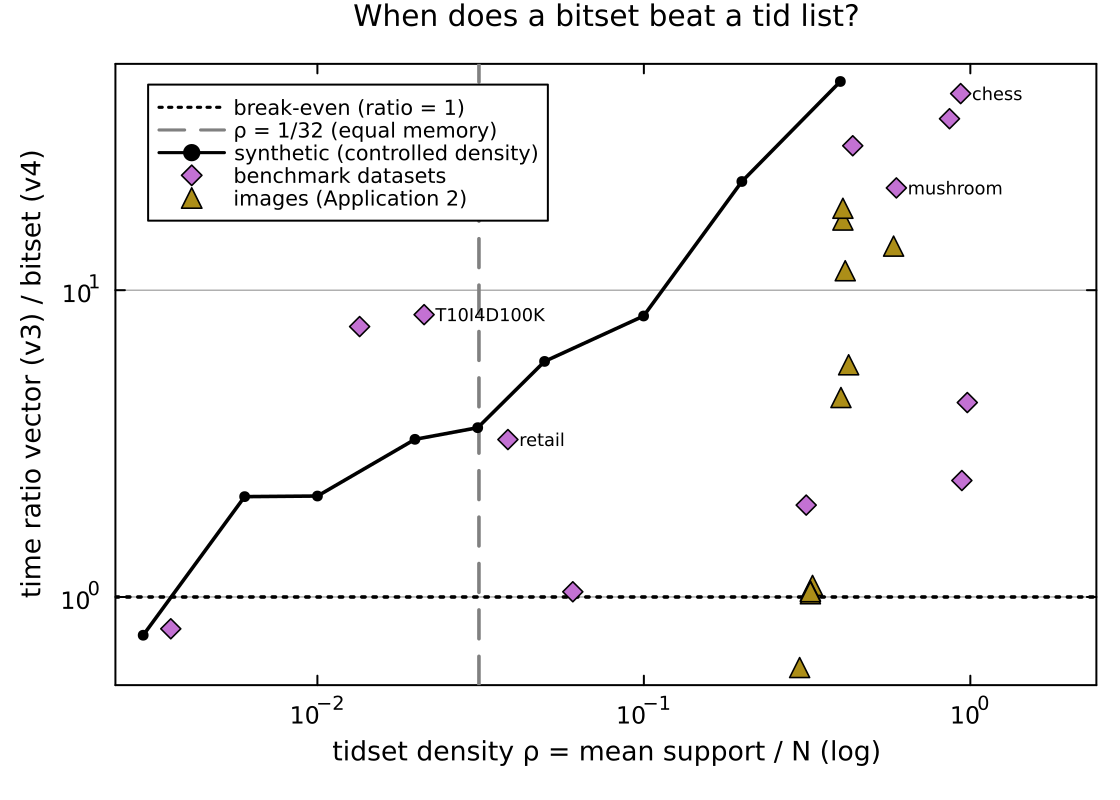

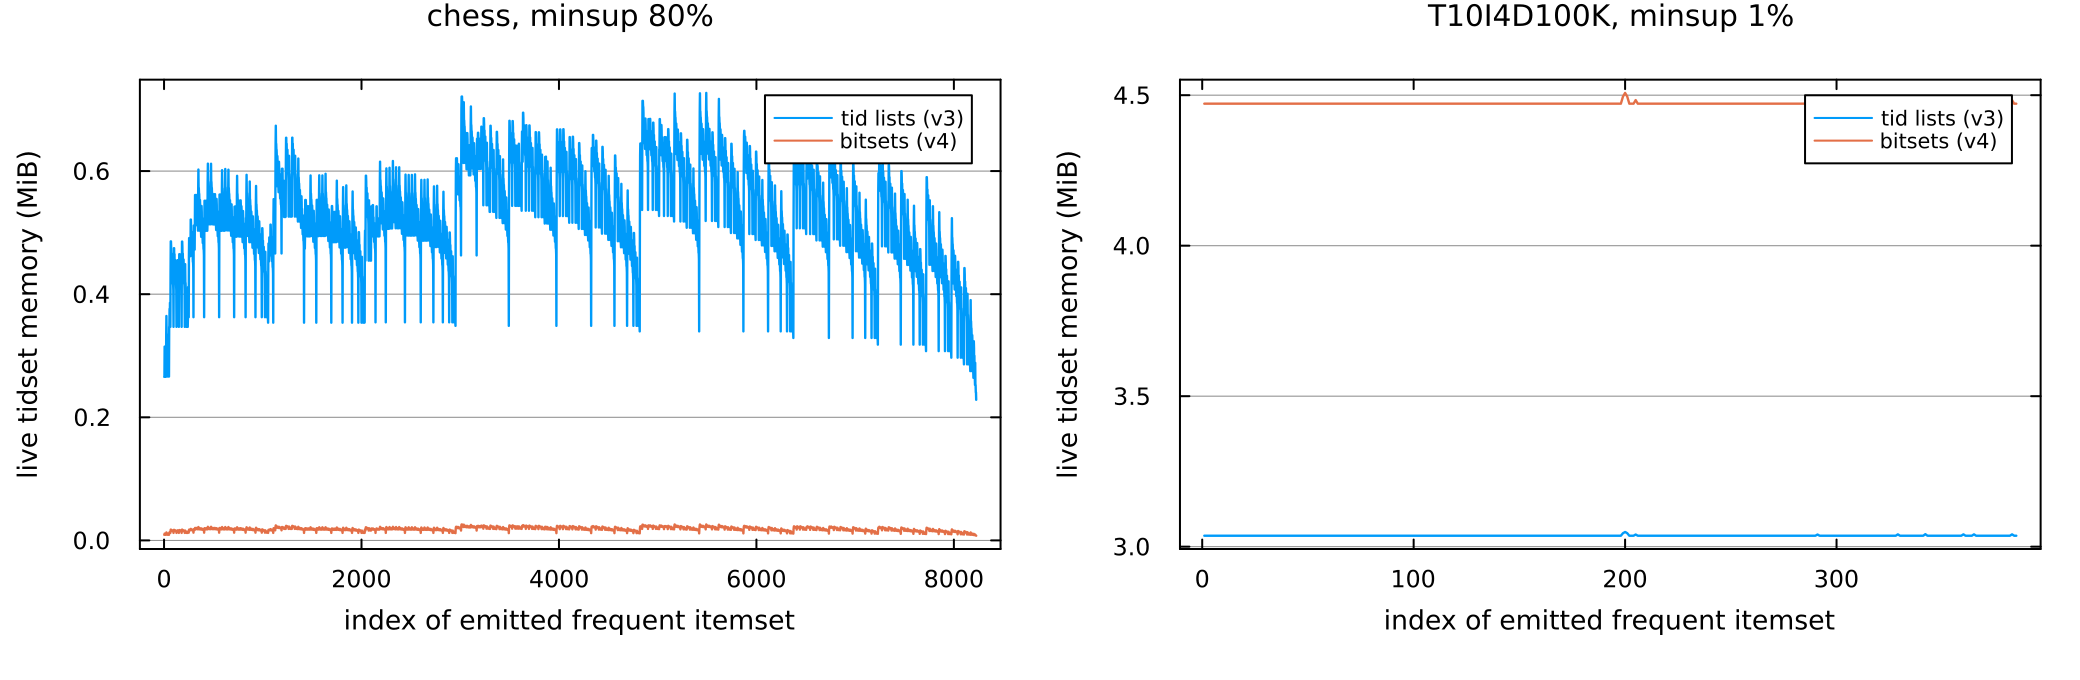

In [8]:
import os
from IPython.display import Markdown, Image, display

os.chdir(REPO_DIR)
os.environ["FIM_RESULTS_DIR"] = "results/colab" if MODE == "quick" else "results"
os.makedirs(os.environ["FIM_RESULTS_DIR"], exist_ok=True)
if MODE == "quick":
    !julia --project=. scripts/bench_ablation.jl --datasets chess --repeats 1
    !julia --project=. scripts/bench_memory_trace.jl chess
else:
    !julia --project=. scripts/bench_ablation.jl --level median
    !julia --project=. scripts/bench_ablation.jl --level low
    !julia --project=. scripts/bench_density.jl
    !julia --project=. scripts/bench_memory_trace.jl
    !julia --project=apps -e "using Pkg; Pkg.instantiate()"
    !julia --project=apps scripts/plots_a.jl
os.environ.pop("FIM_RESULTS_DIR")

# Hiển thị các bảng kết quả và biểu đồ chính thức đã lưu trong kho mã nguồn
for name in ["e8_B03.md", "e8_B03_low.md", "e8_B04.md", "e7_density.md", "e10_memory_trace.md"]:
    with open(os.path.join("results", name), "r", encoding="utf-8") as f:
        display(Markdown(f.read()))
display(Image("results/figures/F08_density_bitset_vs_vector.png", width=600))
display(Image("results/figures/F10_memory_trace.png", width=900))

## Mục 6. Chương 3 -- Ứng dụng 1: Phân tích giỏ hàng trên tập Groceries

Tái hiện toàn bộ quy trình Ứng dụng 1 trên `groceries.csv` (9.835 giao dịch, 169 mặt hàng): so sánh định lượng hai phương án biến đổi dữ liệu (Bảng B08), lưới độ nhạy ngưỡng, top-10 luật kết hợp xếp hạng theo lift (Bảng B09) và đánh giá độ ổn định ngoài mẫu 80/20 (Bảng B10).

In [9]:
import os
from IPython.display import Markdown, display

os.chdir(REPO_DIR)
!julia --project=. scripts/fetch_data.jl groceries
!julia --project=. apps/groceries/run_groceries.jl

with open("results/groceries_summary.md", "r", encoding="utf-8") as f:
    display(Markdown(f.read()))

== groceries
  ↓ tải data/apps/groceries/groceries.csv từ https://huggingface.co/datasets/cuongnguyen0794/16-fim-data-mining/resolve/main/groceries.csv
  ✓ SHA-256 khớp
Xong.
1. Chuẩn bị dữ liệu Groceries (2 phương án biến đổi)...
2. So sánh 2 phương án biến đổi dữ liệu (B08)...
3. Khảo sát độ nhạy lưới minsup × minconf...
4. Trích xuất toàn bộ luật và top-10 theo lift (B09, F11)...
5. Kiểm tra độ ổn định luật trên chia tập 80/20 (seed=42, B10)...
Hoàn tất thực nghiệm Ứng dụng 1. Kết quả tổng hợp lưu tại: /content/16-FIM-DATA-MINING/scripts/../results/groceries_summary.md


# Kết quả Ứng dụng 1: Phân tích giỏ hàng (Groceries)

Sinh bởi `apps/groceries/run_groceries.jl` ngày 2026-11-28 bằng `EclatFIM` (`v6`, seed = 42).

## 1. So sánh phương án biến đổi dữ liệu (Bảng B08)

| Phương án | N | m | L̄ | Mật độ ρ | Tập phổ biến (1%) | Luật (conf ≥ 0,3) | Thời gian (s) |
|---|---:|---:|---:|---:|---:|---:|---:|
| 169 mặt hàng gốc (chọn) | 9835 | 169 | 4.41 | 2.61% | 333 | 125 | 0.0028 |
| Gộp 12 nhóm hàng cấp cao | 9835 | 12 | 3.12 | 25.98% | 477 | 2232 | 0.0022 |

- Phương án 169 mặt hàng gốc có mật độ **2.61%**, tiệm cận ngưỡng cân bằng lý thuyết `1/32 ≈ 3,125%` giữa biểu diễn `Vector` và `BitVector` của Eclat.
- Phương án gom 12 nhóm hàng làm mật độ tăng lên **25.98%**, dẫn đến gia tăng mạnh số tập phổ biến và số luật nhưng làm giảm tính cụ thể của luật.

## 2. Khảo sát độ nhạy trên lưới ngưỡng

| minsup | σ_min | Tập phổ biến | minconf | Số luật | Lift lớn nhất |
|---|---:|---:|---:|---:|---:|
| 0.5% | 50 | 1001 | 0.2 | 893 | 5.212 |
| 0.5% | 50 | 1001 | 0.3 | 487 | 4.716 |
| 0.5% | 50 | 1001 | 0.5 | 120 | 3.691 |
| 1% | 99 | 333 | 0.2 | 234 | 3.295 |
| 1% | 99 | 333 | 0.3 | 125 | 3.295 |
| 1% | 99 | 333 | 0.5 | 15 | 3.03 |
| 2% | 197 | 122 | 0.2 | 73 | 2.842 |
| 2% | 197 | 122 | 0.3 | 37 | 2.842 |
| 2% | 197 | 122 | 0.5 | 1 | 2.007 |

- Cặp ngưỡng **minsup = 1%, minconf = 0.3** được lựa chọn vì tạo ra **125 luật** (thuộc vùng mục tiêu 50–300 luật), cân bằng giữa độ bao phủ và độ tin cậy diễn giải.

## 3. Mười luật kết hợp dẫn đầu theo độ nâng (Bảng B09)

| Hạng | Tiền đề (X) | Hệ quả (Y) | σ | Support | Confidence | Lift |
|---:|---|---|---:|---:|---:|---:|
| 1 | citrus fruit + other vegetables | root vegetables | 102 | 0.0104 | 0.3592 | 3.295 |
| 2 | other vegetables + tropical fruit | root vegetables | 121 | 0.0123 | 0.3428 | 3.145 |
| 3 | beef | root vegetables | 171 | 0.0174 | 0.3314 | 3.04 |
| 4 | citrus fruit + root vegetables | other vegetables | 102 | 0.0104 | 0.5862 | 3.03 |
| 5 | root vegetables + tropical fruit | other vegetables | 121 | 0.0123 | 0.5845 | 3.021 |
| 6 | other vegetables + whole milk | root vegetables | 228 | 0.0232 | 0.3098 | 2.842 |
| 7 | curd + whole milk | yogurt | 99 | 0.0101 | 0.3852 | 2.761 |
| 8 | rolls/buns + root vegetables | other vegetables | 120 | 0.0122 | 0.5021 | 2.595 |
| 9 | root vegetables + yogurt | other vegetables | 127 | 0.0129 | 0.5 | 2.584 |
| 10 | tropical fruit + whole milk | yogurt | 149 | 0.0151 | 0.3582 | 2.568 |

- **Phân tích tiêu chí xếp hạng:** mặt hàng `whole milk` xuất hiện trong **2513/9835 hóa đơn (25.55%)**, khiến các luật đạt confidence cao nhất chủ yếu mang hệ quả `whole milk` nhưng chỉ đạt lift trung bình (1,8–2,3):
  - `citrus fruit + root vegetables ⇒ other vegetables`: conf = 0.586, lift = 3.03
  - `root vegetables + tropical fruit ⇒ other vegetables`: conf = 0.585, lift = 3.021
  - `curd + yogurt ⇒ whole milk`: conf = 0.582, lift = 2.279
  - `butter + other vegetables ⇒ whole milk`: conf = 0.574, lift = 2.245
  - `root vegetables + tropical fruit ⇒ whole milk`: conf = 0.57, lift = 2.231

## 4. Đánh giá độ ổn định trên phép chia 80/20 (Bảng B10, train=7868, test=1967)

| Hạng | Luật (X ⇒ Y) | Train Lift | Test Lift | Biến thiên | Train Conf | Test Conf |
|---:|---|---:|---:|---:|---:|---:|
| 1 | citrus fruit + other vegetables ⇒ root vegetables | 3.325 | 3.175 | -4.5% | 0.361 | 0.352 |
| 2 | other vegetables + tropical fruit ⇒ root vegetables | 3.242 | 2.734 | -15.7% | 0.352 | 0.303 |
| 3 | citrus fruit + root vegetables ⇒ other vegetables | 3.159 | 2.568 | -18.7% | 0.61 | 0.5 |
| 4 | beef ⇒ root vegetables | 3.093 | 2.831 | -8.5% | 0.336 | 0.314 |
| 5 | root vegetables + tropical fruit ⇒ other vegetables | 3.04 | 2.935 | -3.4% | 0.587 | 0.571 |
| 6 | whipped/sour cream + whole milk ⇒ root vegetables | 2.925 | 1.805 | -38.3% | 0.317 | 0.2 |
| 7 | other vegetables + yogurt ⇒ root vegetables | 2.864 | 2.203 | -23.1% | 0.311 | 0.244 |
| 8 | other vegetables + whole milk ⇒ root vegetables | 2.787 | 3.072 | 10.2% | 0.303 | 0.34 |
| 9 | other vegetables + whipped/sour cream ⇒ yogurt | 2.612 | 2.214 | -15.3% | 0.367 | 0.302 |
| 10 | rolls/buns + root vegetables ⇒ other vegetables | 2.588 | 2.628 | 1.5% | 0.5 | 0.512 |

- Toàn bộ **10/10** luật duy trì `test_lift > 1,5` trên tập kiểm tra độc lập 20%.


## Mục 7. Chương 3 -- Ứng dụng 2: Khám phá mẫu trực quan qua Túi từ thị giác (Bag of Visual Words)

**Câu hỏi nghiên cứu:** Các ảnh cùng một lớp đối tượng có chia sẻ những *tổ hợp* đặc trưng thị giác cục bộ lặp lại hay không, và các tổ hợp đó có giúp phân biệt lớp này với lớp khác?

**Quy trình** (`apps/bovw/`, chạy với môi trường `apps/`):

1. `prepare.jl` -- chọn ngẫu nhiên 100 ảnh từ mỗi lớp trong 4 lớp hình dạng rõ nét của Caltech-101 (`airplanes`, `Motorbikes`, `Faces_easy`, `watch`), chia 70/30 huấn luyện/kiểm tra theo từng lớp (seed 42). Ảnh được chuyển xám, chuẩn hóa cạnh dài 256 pixel; 150 mảnh `16×16` có gradient mạnh nhất trên lưới bước 8 được mô tả bằng biểu đồ hướng gradient 128 chiều (`4×4` ô × 8 hướng). Bộ từ điển (*codebook*) gồm *k* ∈ {100, 200, 500} từ thị giác (*visual words*) được học bằng `k-means++` chỉ trên tập huấn luyện, rồi gán mỗi mảnh về từ gần nhất.
2. `analyze.jl` -- chuyển mỗi ảnh thành giao dịch theo 4 phép mã hóa × 3 kích thước *codebook* (Bảng B11), khai thác bằng `EclatFIM` (biến thể mặc định `v6`), chọn cấu hình trên tập thẩm định, khai thác riêng từng lớp và xếp hạng theo tỉ lệ tăng trưởng `GR = s_class / s_other` (*emerging patterns*, Bảng B12), cuối cùng dùng các mẫu phân biệt làm đặc trưng nhị phân cho bộ phân loại đánh giá trên tập kiểm tra (Bảng B13).
3. `figures.jl` -- vẽ các mảnh của mẫu hạng nhất mỗi lớp lên ảnh kiểm tra (Hình F12) và 6 mảnh huấn luyện gần tâm cụm nhất của từng từ thị giác (Hình F13).

**Các thư viện bổ trợ và mục đích sử dụng** (bước khai thác tập phổ biến chỉ dùng gói `EclatFIM` của nhóm; không dùng thư viện FIM hay học máy bên ngoài):

| Thư viện | Mục đích sử dụng |
|---|---|
| `JpegTurbo.jl` | giải mã ảnh JPEG của Caltech-101 |
| `ColorTypes.jl` | chuyển điểm ảnh RGB sang ảnh mức xám |
| `LinearAlgebra` (thư viện chuẩn) | nhân ma trận (BLAS) tính khoảng cách tâm cụm trong `k-means` |
| `Random`, `Statistics` (thư viện chuẩn) | lấy mẫu và chia tập theo hạt giống cố định; trung bình và độ lệch chuẩn |
| `Serialization` (thư viện chuẩn) | lưu đệm bộ mô tả và *codebook* giữa các bước |
| `Printf` (thư viện chuẩn) | định dạng bảng kết quả |
| `Plots.jl` | vẽ các hình F12 và F13 |

Bộ mô tả gradient, `k-means++` và hồi quy logistic đa lớp đều do nhóm tự cài đặt trong `apps/bovw/features.jl` và `apps/bovw/analyze.jl`.

**Dữ liệu:** Caltech-101 (Fei-Fei, Fergus và Perona, 2004; CC BY 4.0), tải tự động bởi `scripts/fetch_data.jl caltech` từ Hugging Face (khoảng 131 MB). Chỉ giải nén 4 lớp nêu trên.

Streaming output truncated to the last 5000 lines.
  ◓ RecipesPipeline
  ◒ HarfBuzz_jll
Precompiling packages  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━ 116/139
  ◑ JSON
  ◑ RecipesPipeline
  ◐ HarfBuzz_jll
Precompiling packages  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━ 116/139
  ◒ JSON
  ◒ RecipesPipeline
  ◓ HarfBuzz_jll
Precompiling packages  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━ 116/139
  ◐ JSON
  ◐ RecipesPipeline
  ◑ HarfBuzz_jll
Precompiling packages  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━ 116/139
  ◓ JSON
  ◓ RecipesPipeline
  ◒ HarfBuzz_jll
Precompiling packages  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━ 116/139
  ◑ JSON
  ◑ RecipesPipeline
  ◐ HarfBuzz_jll
Precompiling packages  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━ 116/139
  ◒ JSON
  ◒ RecipesPipeline
  ◓ HarfBuzz_jll
Precompiling packages  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━ 116/139
  ◐ JSON
  ◐ RecipesPipeline
  ◑ HarfBuzz_jll
Precompiling packages  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━ 116/139
  ◓ JSON
  ◓ RecipesPipeline
  ◒ HarfB

# Application 2: image-to-transaction transformation schemes (Table B11)

Mined on 280 training images, minsup = 30%, itemsets of at most 4 visual words. Times are the minimum of 3 warmed-up mining runs. Accuracy is measured on a validation split (72 images held out from the training set); the test set is not used here.

| k | Encoding | m | L̄ | Density | Itemsets | v3 (vector) | v4 (bitset) | v6 (hybrid) | Val. itemset | Val. histogram |
|---|---|---|---|---|---|---|---|---|---|---|
| 100 | presence, all words | 100 | 56.0 | 56.0% | 48879 | 93.98 ms | 5.29 ms | 6.28 ms | 0.625 | 0.833 |
| 100 | presence, stop words removed | 25 | 9.4 | 37.6% | 34 | 0.10 ms | 0.02 ms | 0.07 ms | 0.667 | 0.833 |
| 100 | stop words removed, plus "occurs ≥ 2 times" items | 50 | 15.0 | 30.0% | 44 | 0.13 ms | 0.04 ms | 0.11 ms | 0.667 | 0.833 |
| 100 | stop words removed, word × image quadrant | 100 | 13.7 | 13.7% | 1 | 0.01 ms | 0.01 ms | 0.01 ms | 0.556 | 0.833 |
| 200 | presence, all words | 200 | 76.2 | 38.1% | 242 | 6.78 ms | 0.37 ms | 1.37 ms | 0.653 | 0.875 |
| 200 | presence, stop words removed | 190 | 71.0 | 37.4% | 171 | 6.38 ms | 0.31 ms | 1.23 ms | 0.667 | 0.875 |
| 200 | stop words removed, plus "occurs ≥ 2 times" items **(selected)** | 380 | 103.1 | 27.1% | 171 | 5.49 ms | 0.34 ms | 1.25 ms | 0.708 | 0.875 |
| 200 | stop words removed, word × image quadrant | 760 | 94.6 | 12.4% | 1 | 0.07 ms | 0.07 ms | 0.06 ms | 0.708 | 0.875 |
| 500 | presence, all words | 500 | 98.7 | 19.7% | 8 | 0.08 ms | 0.08 ms | 0.15 ms | 0.708 | 0.917 |
| 500 | presence, stop words removed | 500 | 98.7 | 19.7% | 8 | 0.08 ms | 0.08 ms | 0.15 ms | 0.708 | 0.917 |
| 500 | stop words removed, plus "occurs ≥ 2 times" items | 1000 | 126.7 | 12.7% | 8 | 0.10 ms | 0.10 ms | 0.19 ms | 0.694 | 0.917 |
| 500 | stop words removed, word × image quadrant | 1995 | 115.4 | 5.8% | 0 | 0.03 ms | 0.03 ms | 0.03 ms | 0.000 | 0.917 |

**Selected scheme:** k = 200, stop words removed, plus "occurs ≥ 2 times" items. Rule: highest validation accuracy with itemset features only; ties go to the smaller k.

# Application 2: discriminative visual-word itemsets per class (Table B12)

Scheme: k = 200, stop words removed, plus "occurs ≥ 2 times" items. Each class is mined separately on its training images (minsup = 30% of the class, itemsets of 2–3 words), ranked by growth rate GR = s_class / s_other (∞: never occurs in another class, a "jumping emerging pattern"). Notation `w×2`: visual word w occurs at least twice in the image (item code 200 + w).

## airplanes (3089 frequent itemsets in the class)

| # | Visual words | s (this class) | s (other classes) | GR |
|---|---|---|---|---|
| 1 | 31, 41, 146 | 0.36 | 0.000 | ∞ |
| 2 | 31, 146, 171 | 0.36 | 0.000 | ∞ |
| 3 | 118, 146, 146×2 | 0.36 | 0.000 | ∞ |
| 4 | 118, 146×2 | 0.36 | 0.000 | ∞ |
| 5 | 41, 101, 118×2 | 0.33 | 0.000 | ∞ |

## Motorbikes (13134 frequent itemsets in the class)

| # | Visual words | s (this class) | s (other classes) | GR |
|---|---|---|---|---|
| 1 | 63, 139, 192 | 0.31 | 0.005 | 66.0 |
| 2 | 12, 57, 192×2 | 0.30 | 0.005 | 63.0 |
| 3 | 120, 189, 192 | 0.37 | 0.010 | 39.0 |
| 4 | 2, 20, 182 | 0.31 | 0.010 | 33.0 |
| 5 | 29, 120, 137 | 0.31 | 0.010 | 33.0 |

## Faces_easy (4881 frequent itemsets in the class)

| # | Visual words | s (this class) | s (other classes) | GR |
|---|---|---|---|---|
| 1 | 56, 73, 113 | 0.36 | 0.000 | ∞ |
| 2 | 87, 126, 167 | 0.36 | 0.000 | ∞ |
| 3 | 22, 166, 187 | 0.34 | 0.000 | ∞ |
| 4 | 59, 110, 110×2 | 0.34 | 0.000 | ∞ |
| 5 | 59, 110×2 | 0.34 | 0.000 | ∞ |

## watch (6645 frequent itemsets in the class)

| # | Visual words | s (this class) | s (other classes) | GR |
|---|---|---|---|---|
| 1 | 44, 72, 191×2 | 0.30 | 0.010 | 31.5 |
| 2 | 15, 74, 129×2 | 0.31 | 0.014 | 22.0 |
| 3 | 72, 115, 164×2 | 0.30 | 0.014 | 21.0 |
| 4 | 72, 191, 44×2 | 0.30 | 0.014 | 21.0 |
| 5 | 23, 72, 164×2 | 0.33 | 0.019 | 17.2 |


# Application 2: frequent visual patterns as classifier features (Table B13)

Multinomial logistic regression (own implementation), 280 training images, 120 test images, 4 classes. Discriminative patterns are mined on training images only.

| Features | Dimensions | Test accuracy |
|---|---|---|
| Histogram bag of visual words (k = 200) | 200 | 0.858 |
| Discriminative itemsets (20 per class) | 80 | 0.758 |
| Both combined | 280 | 0.867 |

Confusion matrix of the itemset features (rows: true class, columns: predicted class; order airplanes, Motorbikes, Faces_easy, watch):

| | airplanes | Motorbikes | Faces_easy | watch |
|---|---|---|---|---|
| airplanes | 29 | 1 | 0 | 0 |
| Motorbikes | 3 | 22 | 1 | 4 |
| Faces_easy | 2 | 2 | 24 | 2 |
| watch | 3 | 7 | 4 | 16 |


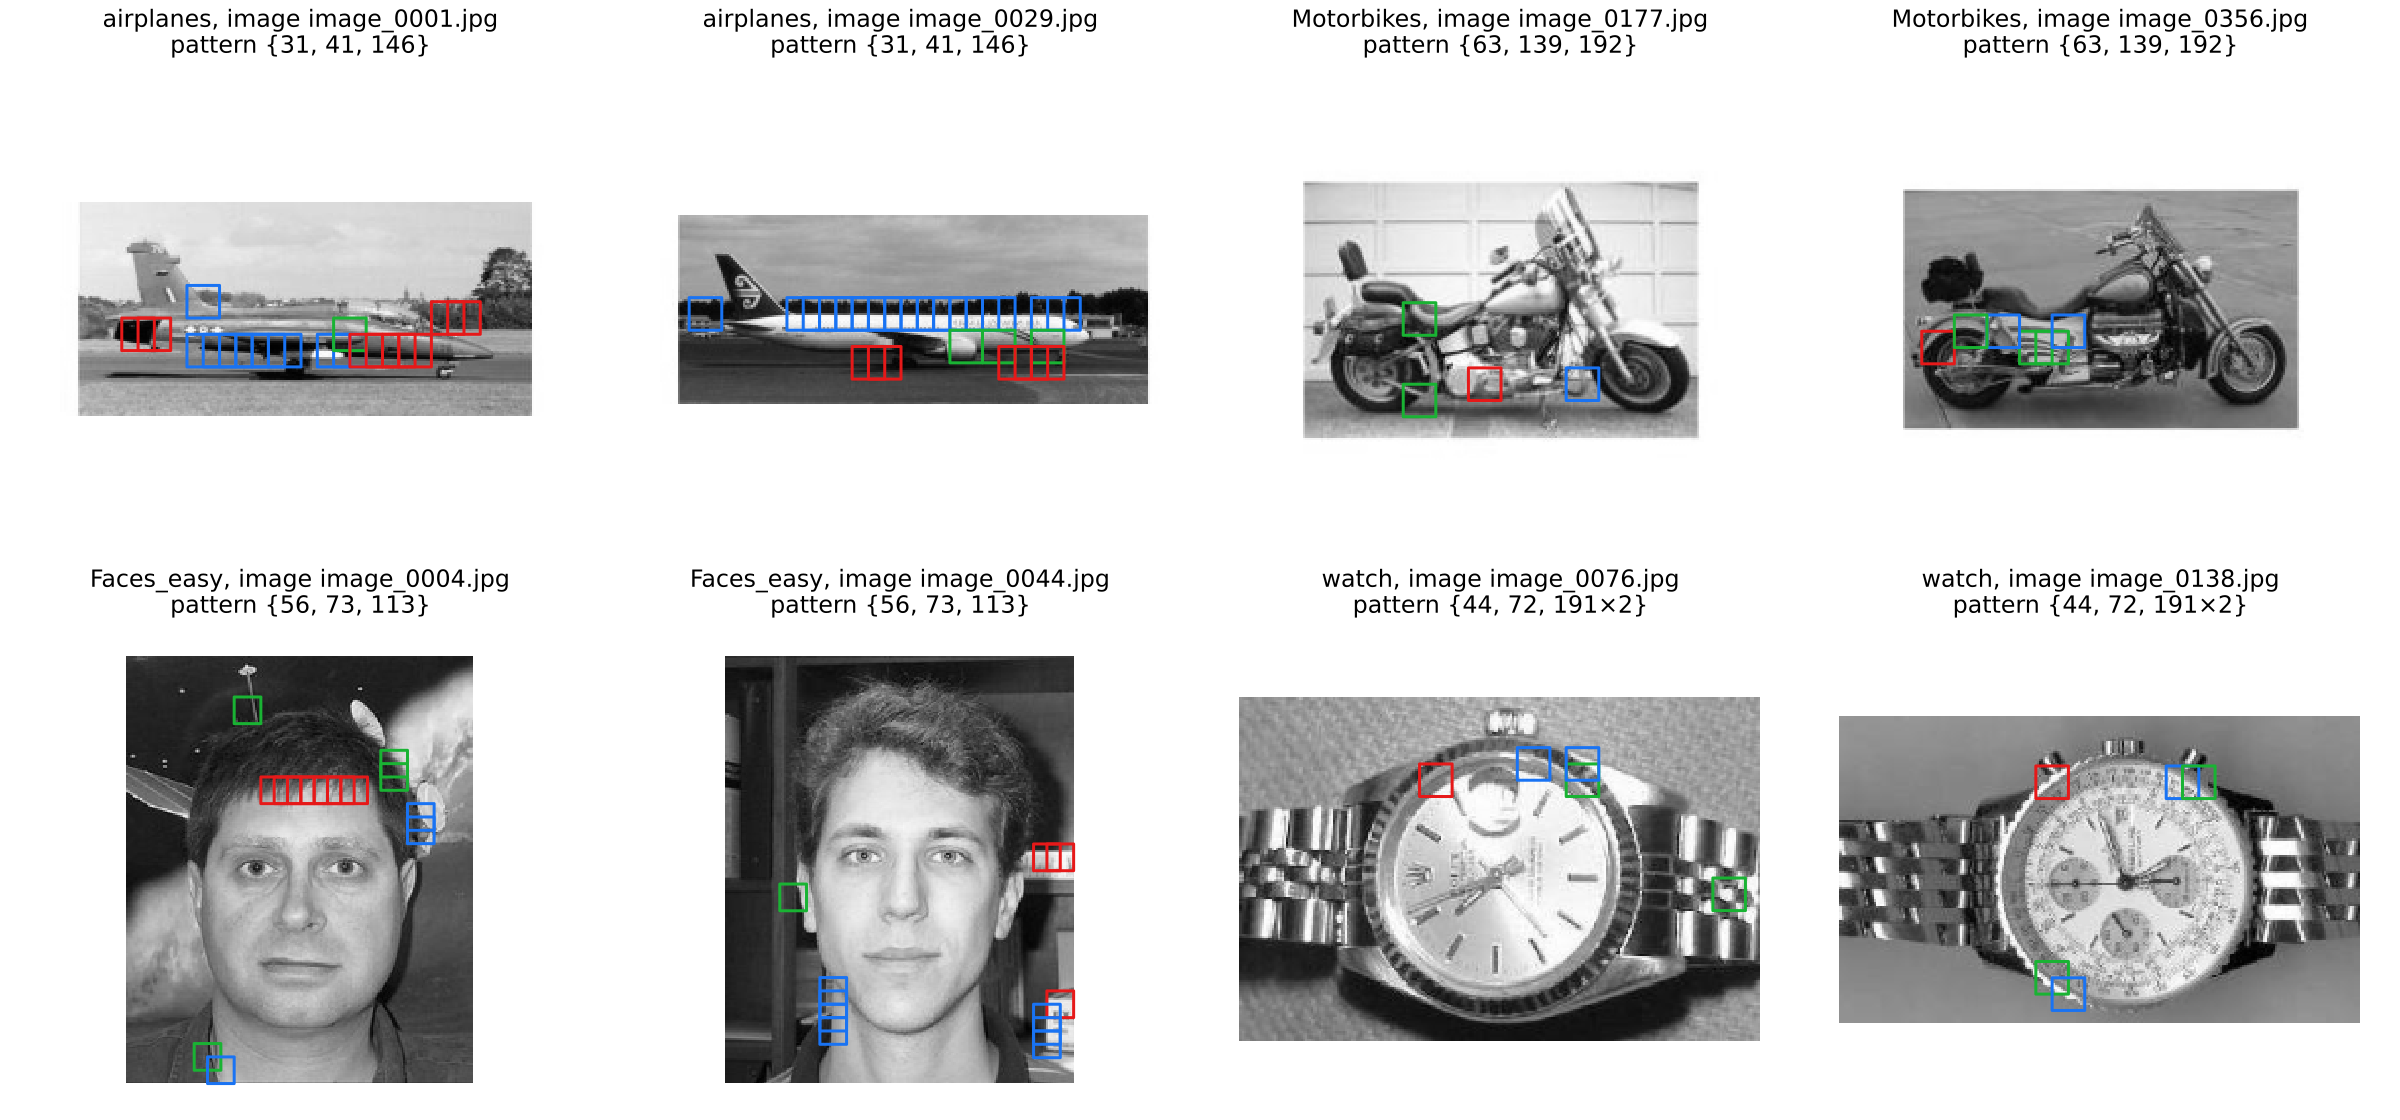

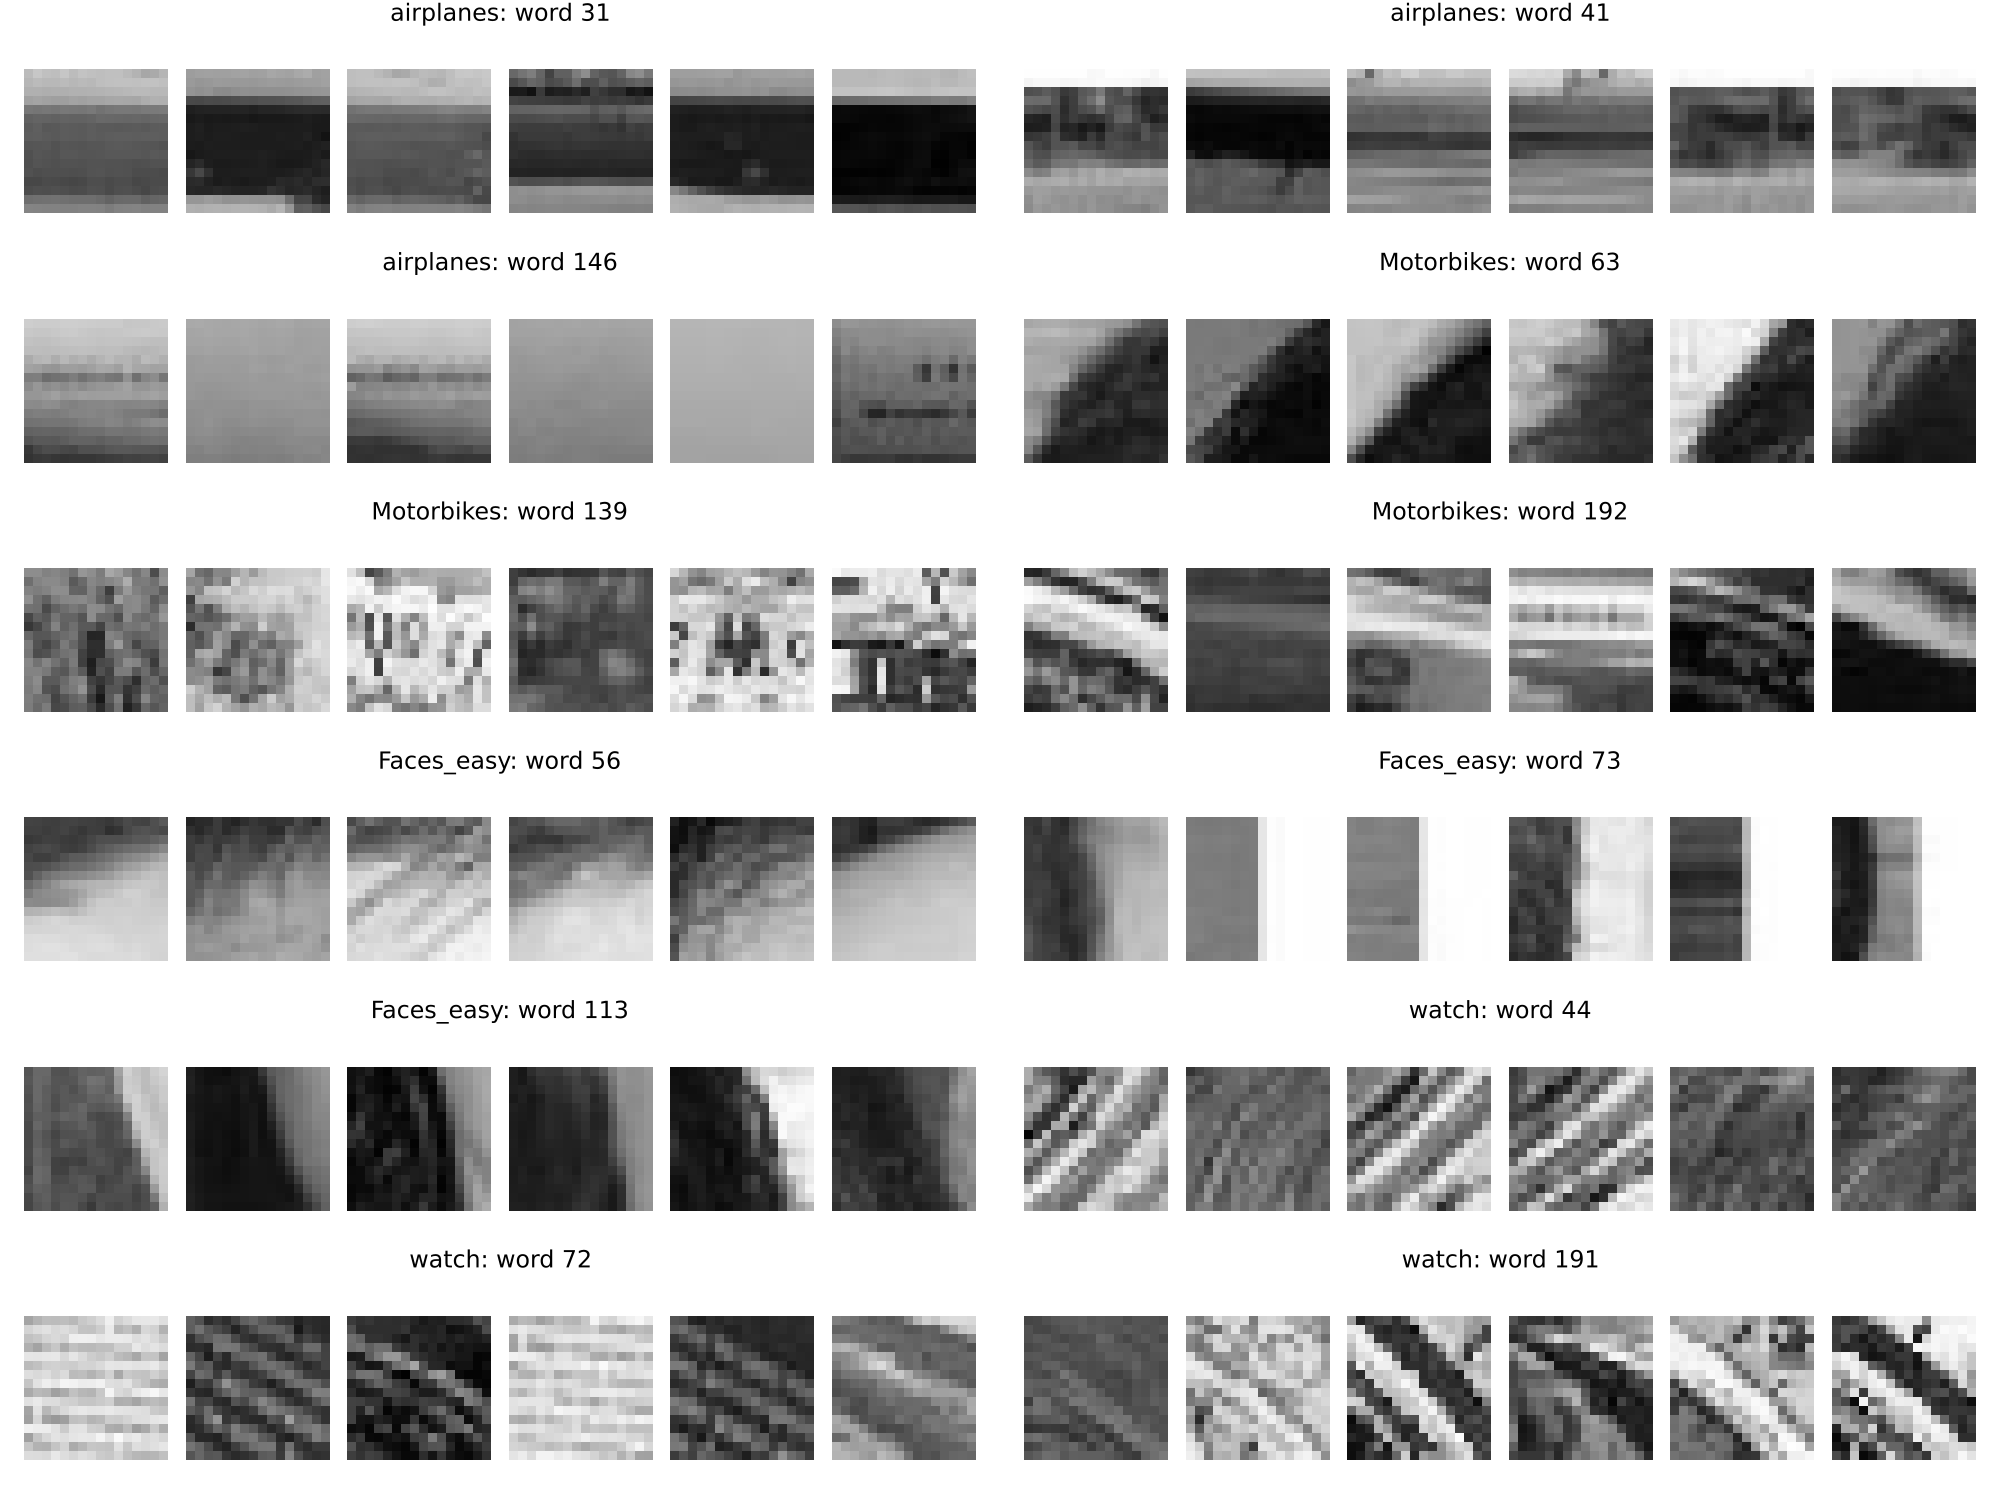

In [10]:
import os
from IPython.display import Markdown, Image, display

os.chdir(REPO_DIR)
!julia --project=apps -e "using Pkg; Pkg.instantiate(); Pkg.precompile()"
!julia --project=. scripts/fetch_data.jl caltech
!julia --project=apps apps/bovw/prepare.jl
!julia --project=apps apps/bovw/analyze.jl
!julia --project=apps apps/bovw/figures.jl

with open("results/bovw_summary.md", "r", encoding="utf-8") as f:
    display(Markdown(f.read()))
display(Image("results/figures/F12_bovw_patterns_on_images.png", width=950))
display(Image("results/figures/F13_bovw_visual_words.png", width=750))

## Mục 8. Báo cáo và Các tệp kết quả

Báo cáo đầy đủ của đồ án (định dạng IEEE Conference Format, tiếng Việt) được lưu tại `docs/Report.pdf` trong kho mã nguồn này.